<a href="https://colab.research.google.com/github/joseaespinosa02/glassdoor-nlp-dhl/blob/main/Glassdoor_DHL_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diagnóstico de marca empleadora — DHL Supply Chain vs. peers
## Sentimiento (DistilBERT) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar puntos fuertes y áreas de mejora de **DHL Supply Chain** como empleador a partir de Glassdoor, comparados con sus competidores directos.

**Peers:** UPS, FedEx, MAERSK, DB-Schenker y Kuehne+Nagel. Todos son operadores logísticos globales (paquetería, freight forwarding, contract logistics) que compiten por el mismo talento: operarios de almacén y transporte, supervisores de operaciones, planificadores y perfiles de supply chain. Todos superan las 300 reseñas.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic |
| 4 | Comparación con peers (balance neto) |
| 5 | Empleados actuales vs. antiguos |
| 6 | Matriz de priorización + extras (evolución pre/post 2020, antigüedad) |
| 7 | Conclusiones y recomendaciones para RRHH |

In [64]:
# Colab (Entorno > Cambiar tipo de entorno > GPU). transformers ya viene instalado; BERTopic no.
!pip install -q bertopic sentence-transformers

---
## 0. Carga y preparación

In [65]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

TARGET = 'DHL-Supply-Chain'
# Solo la entidad 'DHL-Supply-Chain': hay otras (DHL, DHL-Global-Forwarding, Deutsche-Post-&-DHL)
# que son negocios distintos (paquetería/forwarding); mezclarlas diluiría el diagnóstico.
PEERS = ['UPS', 'FedEx', 'MAERSK', 'DB-Schenker', 'Kuehne+Nagel']
FIRMS = [TARGET] + PEERS

# Tope de 2.000 reseñas por empresa con semilla fija: UPS tiene ~17.500 y dominaría
# el modelo de topics conjunto; además acota el tiempo de DistilBERT/BERTopic.
MAX_POR_EMPRESA = 2000
SEED = 42

# Localización del dataset: carpeta actual o Google Drive (en Colab subir 286 MB por el panel es lento,
# por eso se admite tenerlo en "Mi unidad" y montar Drive).
import os
RUTA = 'glassdoor_reviews_hr.parquet'
if not os.path.exists(RUTA):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        RUTA = '/content/drive/MyDrive/glassdoor_reviews_hr.parquet'
    except ImportError:
        pass
assert os.path.exists(RUTA), f'No encuentro el dataset en {RUTA}: súbelo a la carpeta de trabajo o a Mi unidad de Google Drive'

raw = pd.read_parquet(RUTA, filters=[('firm', 'in', FIRMS)])
print('Reseñas disponibles por empresa:')
print(raw['firm'].value_counts())
print('\nNulos por columna:\n', raw.isna().sum())

# DECISIÓN: DHL-Supply-Chain solo tiene reseñas hasta junio 2021; los peers llegan a 2023.
# Recortamos todas las empresas a la misma ventana para que la comparación sea justa:
# si no, compararíamos a DHL (2018-2021) con peers que incluyen la crisis logística de 2022.
# Alternativa descartada: unir entidades DHL (paquetería/forwarding = otro negocio y otro perfil).
raw['date_review'] = pd.to_datetime(raw['date_review'])
FIN = raw.loc[raw['firm'] == TARGET, 'date_review'].max()
raw = raw[raw['date_review'] <= FIN]
print(f'\nVentana común: {raw.date_review.min():%Y-%m-%d} -> {FIN:%Y-%m-%d}')
print(raw['firm'].value_counts())

Reseñas disponibles por empresa:
firm
UPS                 17503
FedEx                5039
MAERSK               2976
DHL-Supply-Chain     1687
DB-Schenker          1312
Kuehne+Nagel          926
Name: count, dtype: int64

Nulos por columna:
 firm              0
date_review       0
current           0
overall_rating    0
recommend         0
pros              0
cons              0
dtype: int64

Ventana común: 2018-07-27 -> 2021-06-05
firm
UPS                 8438
FedEx               2669
DHL-Supply-Chain    1687
MAERSK              1304
DB-Schenker          602
Kuehne+Nagel         471
Name: count, dtype: int64


In [66]:
# Limpieza previa al muestreo
for col in ['pros', 'cons']:
    raw[col] = raw[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

n0 = len(raw)
raw = raw.drop_duplicates(subset=['firm', 'pros', 'cons'])           # duplicados exactos
raw = raw[(raw['pros'].str.len() >= 3) & (raw['cons'].str.len() >= 3)]  # textos vacíos o 'nan'
print(f'Eliminadas {n0 - len(raw):,} filas duplicadas o sin texto')

df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
print(f'Muestra de trabajo: {len(df):,} reseñas')
print(df['firm'].value_counts())

Eliminadas 2 filas duplicadas o sin texto
Muestra de trabajo: 8,063 reseñas
firm
UPS                 2000
FedEx               2000
DHL-Supply-Chain    1687
MAERSK              1303
DB-Schenker          602
Kuehne+Nagel         471
Name: count, dtype: int64


La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables y traduzco `recommend` (v = sí, o = sin opinión, x = no).

In [67]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'): return 'Actual'
    if s.startswith('former'):  return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['situacion']  = df['current'].map(situacion)
df['antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year
df['es_target'] = np.where(df['firm'] == TARGET, TARGET, 'Peers')

print(df['situacion'].value_counts(), '\n')
print(df['antiguedad'].value_counts())
df[['firm','date_review','situacion','antiguedad','overall_rating','recomienda','pros','cons']].head()

situacion
Actual     4543
Antiguo    3520
Name: count, dtype: int64 

antiguedad
n/d              3046
more than 1y     1428
less than 1y     1375
more than 3y      964
more than 5y      557
more than 10y     434
more than 8y      259
Name: count, dtype: int64


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,DB-Schenker,2019-05-05,Antiguo,n/d,3.0,Sí,Big Multi-National Company in the logistics industry.,A long working hour and company politics.
1,DB-Schenker,2021-01-20,Antiguo,n/d,4.0,Neutral,many breaks for the job,long hours in a day
2,DB-Schenker,2021-05-04,Antiguo,more than 1y,2.0,No,- Decent benefits - Salary increase,- Extremely bad management - Lack of transparency - People are not promoted fairly - Employees of the SSC are treate...
3,DB-Schenker,2019-02-28,Actual,n/d,3.0,Neutral,- international company - great people working with our customers,- highly political - too many prioritized topics
4,DB-Schenker,2019-10-28,Antiguo,less than 1y,3.0,No,- environment and supervisors - company lunches,- wages (below industry) - parking a huge issue (had to arrive 30 mins early just to find a place to park)


---
## 1. EDA
### 1.1 Resumen por empresa

In [68]:
resumen = (df.groupby('firm')
    .agg(n_resenas=('firm', 'size'),
         rating_medio=('overall_rating', 'mean'),
         pct_recomienda=('recommend', lambda s: (s == 'v').mean() * 100),
         pct_no_recomienda=('recommend', lambda s: (s == 'x').mean() * 100),
         pct_actuales=('situacion', lambda s: (s == 'Actual').mean() * 100))
    .round(2).sort_values('rating_medio', ascending=False))
# % recomienda calculado sobre el total (incluye 'sin opinión'), igual para todas las firmas
resumen

,n_resenas,rating_medio,pct_recomienda,pct_no_recomienda,pct_actuales
firm,,,,,
MAERSK,1303,3.98,59.09,14.35,55.49
FedEx,2000,3.72,46.25,17.90,57.80
Kuehne+Nagel,471,3.53,53.29,26.96,60.72
DHL-Supply-Chain,1687,3.52,44.16,25.84,57.50
UPS,2000,3.49,40.50,26.50,54.20
DB-Schenker,602,3.24,39.87,34.55,53.82


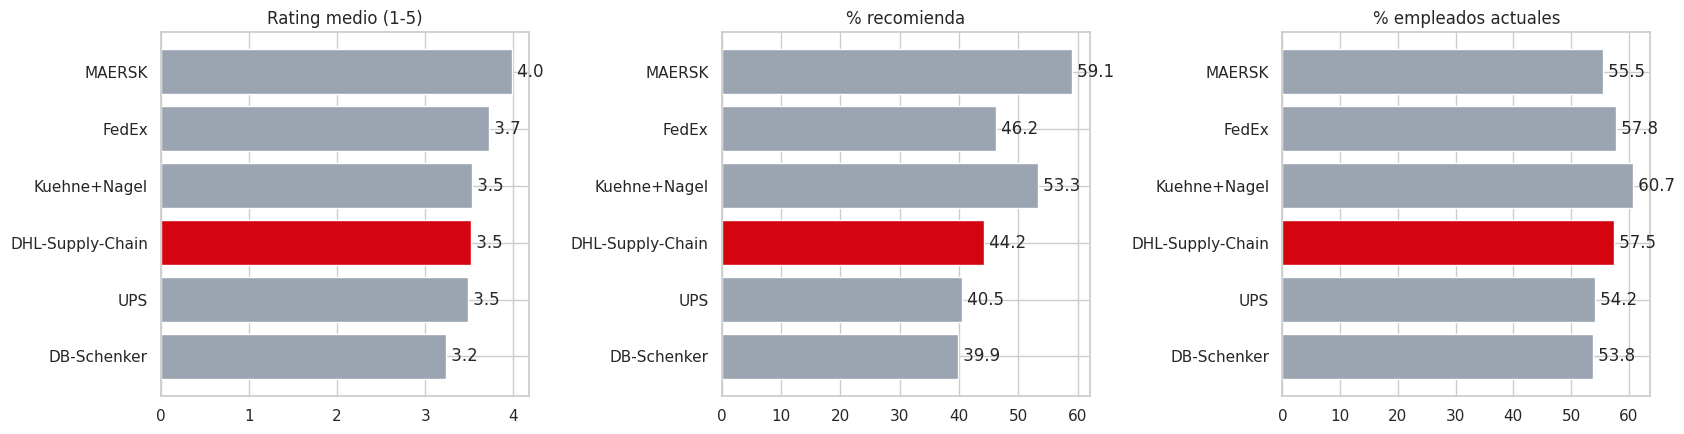

In [69]:
orden = resumen.index.tolist()
colores = ['#D40511' if f == TARGET else '#9aa5b1' for f in orden]   # rojo DHL para destacar
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, tit in zip(axes, ['rating_medio', 'pct_recomienda', 'pct_actuales'],
                        ['Rating medio (1-5)', '% recomienda', '% empleados actuales']):
    ax.barh(orden, resumen[col], color=colores)
    ax.set_title(tit); ax.invert_yaxis()
    for i, v in enumerate(resumen[col]): ax.text(v, i, f' {v:.1f}', va='center')
plt.tight_layout(); plt.show()

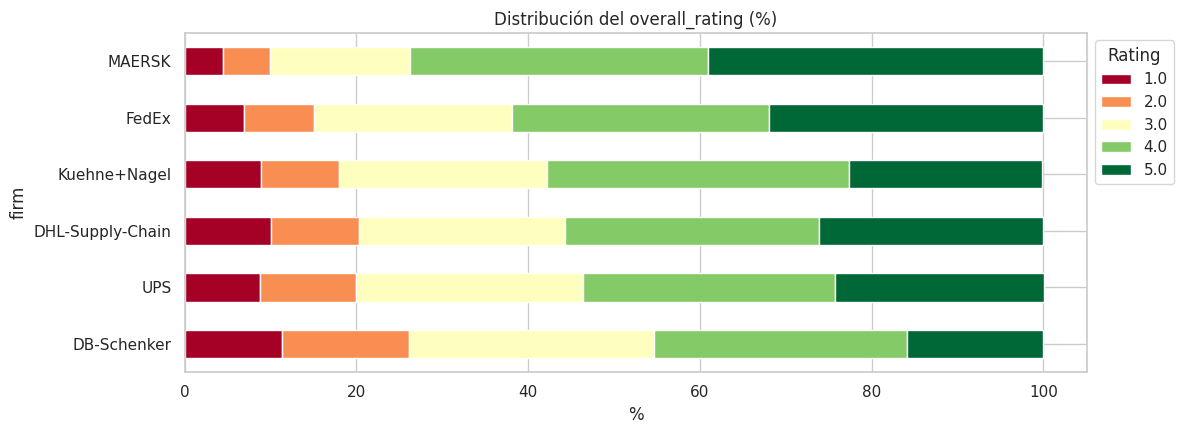

overall_rating,1.0,2.0,3.0,4.0,5.0
firm,,,,,
MAERSK,4.5,5.4,16.3,34.8,39.0
FedEx,6.9,8.2,23.0,29.9,32.0
Kuehne+Nagel,8.9,9.1,24.2,35.2,22.5
DHL-Supply-Chain,10.1,10.2,24.0,29.6,26.1
UPS,8.8,11.2,26.4,29.4,24.3
DB-Schenker,11.3,14.8,28.6,29.4,15.9


In [70]:
# Distribución del rating: ¿la media esconde polarización?
dist = pd.crosstab(df['firm'], df['overall_rating'], normalize='index').mul(100).round(1).loc[orden]
dist.plot(kind='barh', stacked=True, figsize=(12, 4.5), colormap='RdYlGn')
plt.title('Distribución del overall_rating (%)'); plt.xlabel('%'); plt.gca().invert_yaxis()
plt.legend(title='Rating', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
dist

### 1.2 Empleados actuales vs. antiguos

In [71]:
act_ant = df.pivot_table(index='firm', columns='situacion', values='overall_rating', aggfunc='mean').loc[orden]
act_ant['gap'] = act_ant['Actual'] - act_ant['Antiguo']
act_ant.round(2)

situacion,Actual,Antiguo,gap
firm,,,
MAERSK,4.12,3.81,0.32
FedEx,3.86,3.53,0.32
Kuehne+Nagel,3.76,3.18,0.58
DHL-Supply-Chain,3.69,3.28,0.41
UPS,3.59,3.38,0.21
DB-Schenker,3.46,2.99,0.47


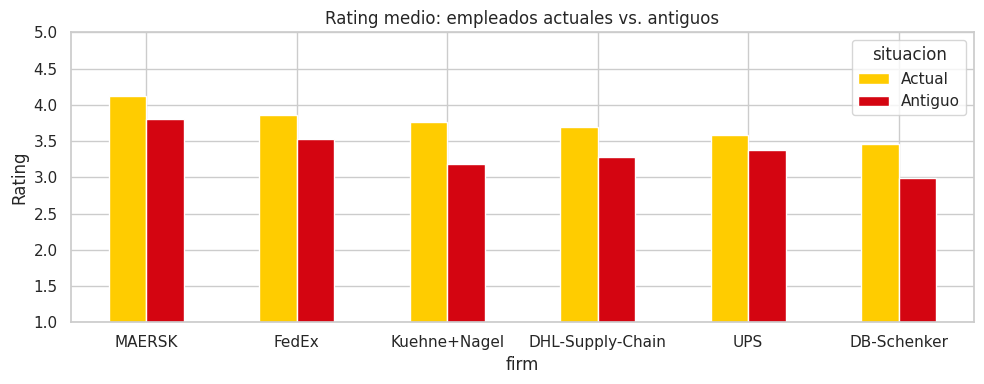

In [72]:
act_ant[['Actual', 'Antiguo']].plot(kind='bar', figsize=(10, 4), color=['#FFCC00', '#D40511'])
plt.title('Rating medio: empleados actuales vs. antiguos'); plt.ylabel('Rating'); plt.ylim(1, 5)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

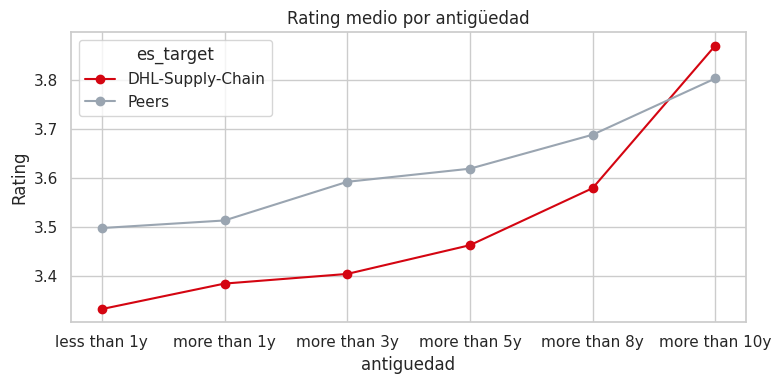

es_target,DHL-Supply-Chain,Peers
antiguedad,,
less than 1y,3.33,3.50
more than 1y,3.39,3.51
more than 3y,3.40,3.59
more than 5y,3.46,3.62
more than 8y,3.58,3.69
more than 10y,3.87,3.80


In [73]:
# Rating por antigüedad (solo reseñas que la informan)
ant_ord = ['less than 1y', 'more than 1y', 'more than 3y', 'more than 5y', 'more than 8y', 'more than 10y']
antig = (df[df['antiguedad'] != 'n/d']
         .pivot_table(index='antiguedad', columns='es_target', values='overall_rating', aggfunc='mean')
         .reindex(ant_ord))
antig.plot(marker='o', figsize=(8, 4), color=['#D40511', '#9aa5b1'])
plt.title('Rating medio por antigüedad'); plt.ylabel('Rating'); plt.tight_layout(); plt.show()
antig.round(2)

### 1.3 Evolución del rating

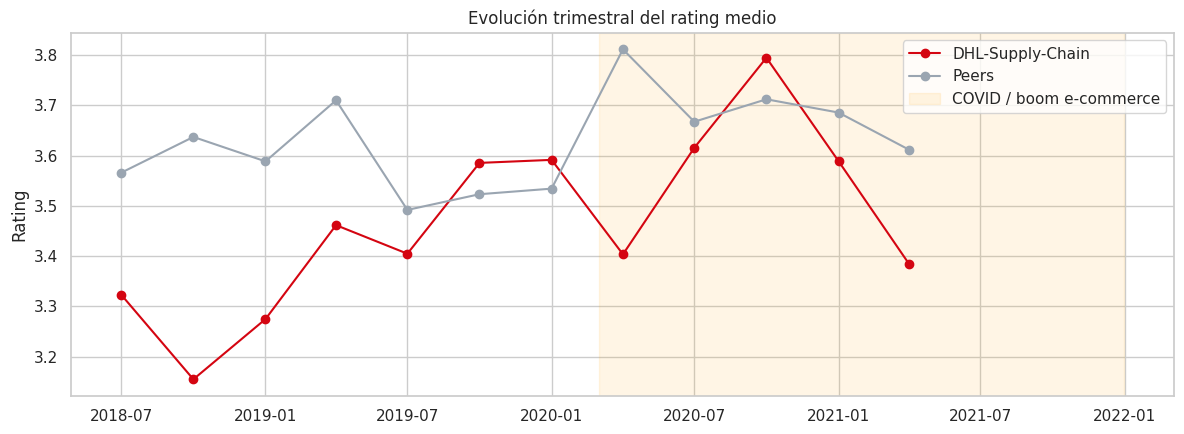

In [74]:
df['trimestre'] = df['date_review'].dt.to_period('Q').dt.to_timestamp()
evo = df.groupby(['trimestre', 'es_target'])['overall_rating'].agg(['mean', 'size']).reset_index()
# Trimestres con menos de 30 reseñas son ruido: se excluyen del gráfico
evo = evo[evo['size'] >= 30]

fig, ax = plt.subplots(figsize=(12, 4.5))
for grupo, c in [(TARGET, '#D40511'), ('Peers', '#9aa5b1')]:
    d = evo[evo['es_target'] == grupo]
    ax.plot(d['trimestre'], d['mean'], marker='o', label=grupo, color=c)
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-31'), alpha=0.1, color='orange', label='COVID / boom e-commerce')
ax.set_title('Evolución trimestral del rating medio'); ax.set_ylabel('Rating'); ax.legend()
plt.tight_layout(); plt.show()

In [75]:
por_anio = df.pivot_table(index='anio', columns='firm', values='overall_rating', aggfunc='mean')[orden]
print('Nº de reseñas por año:'); print(pd.crosstab(df['anio'], df['firm'])[orden], '\n')
por_anio.round(2)

Nº de reseñas por año:
firm  MAERSK  FedEx  Kuehne+Nagel  DHL-Supply-Chain  UPS  DB-Schenker
anio                                                                 
2018     124    144            20               136  207           55
2019     338    441           109               403  436          151
2020     429    673           178               512  652          188
2021     412    742           164               636  705          208 



firm,MAERSK,FedEx,Kuehne+Nagel,DHL-Supply-Chain,UPS,DB-Schenker
anio,,,,,,
2018,3.97,3.80,3.30,3.24,3.39,3.20
2019,3.97,3.69,3.41,3.43,3.39,3.07
2020,3.93,3.74,3.44,3.66,3.61,3.37
2021,4.06,3.70,3.74,3.51,3.49,3.25


### Conclusiones del EDA (ventana común jul-2018 → jun-2021)
- **Posición media-baja:** DHL Supply Chain (3,52) es 4ª de 6, empatada con Kuehne+Nagel y por delante solo de UPS y DB-Schenker. MAERSK (3,98) es el *benchmark* del sector. **Acción:** estudiar qué hace MAERSK distinto (secciones 3-4).
- **Polarización:** un 20 % de reseñas de DHL son de 1-2 estrellas (MAERSK ~10 %, FedEx ~15 %). Hay un grupo de empleados muy descontento → hay que identificar sus quejas en los cons.
- **Recomendación:** solo el 44 % recomienda DHL y un 26 % dice explícitamente que no (vs 18 % en FedEx). La reputación boca a boca afecta directamente a la atracción de talento.
- **Antigüedad:** DHL puntúa por debajo de los peers en todos los tramos de 1 a 8 años y solo supera a los peers con >10 años. **Acción:** el riesgo de fuga está en los perfiles de antigüedad media; hipótesis a validar con topics: carrera/promoción.
- **Actuales vs antiguos:** el gap (0,41) está en la media del sector → la pérdida de satisfacción al salir no es anómala.
- **Evolución:** DHL mejora en 2020 (3,66, pico del boom e-commerce/COVID) y retrocede en 2021 (3,51) mientras Kuehne+Nagel y MAERSK suben. Señal de alerta temprana.
- **Limitación:** DHL no tiene reseñas en el dataset tras jun-2021, por lo que todo el análisis se hace en la ventana común.

---
## 2. Sentimiento en pros y cons (control de calidad)

Uso `distilbert-base-uncased-finetuned-sst-2-english`: modelo transformer preentrenado, binario (POSITIVE/NEGATIVE), rápido y el sugerido en clase. **Por qué binario sirve aquí:** no queremos medir matices, sino comprobar que los textos de *pros* son mayoritariamente positivos y los de *cons* negativos. Si no lo fueran, habría un problema de limpieza o de datos que contaminaría los topics.

`truncation=True` corta en 512 tokens (las reseñas largas son pocas y su tono suele estar claro al principio).

In [76]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print('GPU disponible:', torch.cuda.is_available())

clf = pipeline('sentiment-analysis',
               model='distilbert-base-uncased-finetuned-sst-2-english',
               device=device, truncation=True, max_length=512)

def predecir(textos, batch_size=64):
    out = clf(list(textos), batch_size=batch_size)
    return [o['label'] for o in out], [o['score'] for o in out]

# En Colab con GPU tarda ~2-4 min para ~16.000 textos
df['sent_pros'], df['score_pros'] = predecir(df['pros'])
df['sent_cons'], df['score_cons'] = predecir(df['cons'])
df.to_parquet('df_sentimiento.parquet')   # checkpoint para no recalcular

GPU disponible: True


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [77]:
calidad = (df.groupby('firm')
    .agg(pct_pros_positivos=('sent_pros', lambda s: (s == 'POSITIVE').mean() * 100),
         pct_cons_negativos=('sent_cons', lambda s: (s == 'NEGATIVE').mean() * 100))
    .round(1).loc[orden])
calidad.loc['TOTAL'] = [(df.sent_pros == 'POSITIVE').mean() * 100, (df.sent_cons == 'NEGATIVE').mean() * 100]
calidad.round(1)

,pct_pros_positivos,pct_cons_negativos
firm,,
MAERSK,92.6,77.4
FedEx,89.4,79.6
Kuehne+Nagel,93.2,83.9
DHL-Supply-Chain,87.8,81.7
UPS,88.1,83.8
DB-Schenker,86.0,86.0
TOTAL,89.2,81.5


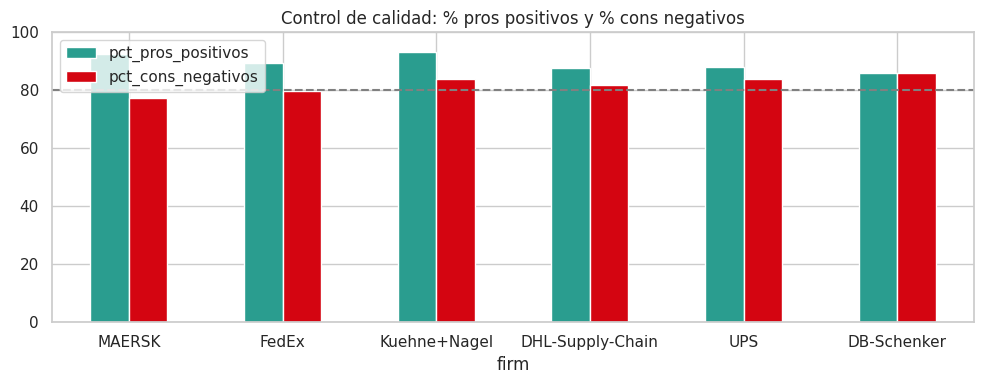

In [78]:
ax = calidad.drop('TOTAL').plot(kind='bar', figsize=(10, 4), color=['#2a9d8f', '#D40511'])
ax.axhline(80, ls='--', c='grey'); ax.set_ylim(0, 100)
ax.set_title('Control de calidad: % pros positivos y % cons negativos'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### Casos discordantes

In [79]:
pd.set_option('display.max_colwidth', 200)
cons_pos = df[df['sent_cons'] == 'POSITIVE']
pros_neg = df[df['sent_pros'] == 'NEGATIVE']
print(f'Cons clasificados como POSITIVOS: {len(cons_pos):,} ({len(cons_pos)/len(df):.1%})')
print(f'Pros clasificados como NEGATIVOS: {len(pros_neg):,} ({len(pros_neg)/len(df):.1%})')

print('\n--- Cons POSITIVOS (muestra) ---')
display(cons_pos.sample(10, random_state=SEED)[['firm', 'cons', 'score_cons']])
print('\n--- Pros NEGATIVOS (muestra) ---')
display(pros_neg.sample(10, random_state=SEED)[['firm', 'pros', 'score_pros']])

Cons clasificados como POSITIVOS: 1,494 (18.5%)
Pros clasificados como NEGATIVOS: 867 (10.8%)

--- Cons POSITIVOS (muestra) ---


,firm,cons,score_cons
5109,MAERSK,Undergoing significant change program,0.990652
4877,MAERSK,"Management, bonus, opinions, many projects",0.998510
7060,UPS,I enjoy the work load,0.999791
5229,MAERSK,Job is a bit stressful sometimes especially when the urgency of requirements are needed in a not so convenient location. Good thing you have a team who can also assist you.,0.988707
5138,MAERSK,no cons for this company,0.995271
3098,FedEx,No downside from this company. Great company,0.997271
2705,FedEx,Long hours Transportation High Goals,0.991454
1735,DHL-Supply-Chain,Micro management by senior management,0.946079
1963,DHL-Supply-Chain,They aren’t disclosing that they have active cases of corona in the building before hiring,0.916808
1370,DHL-Supply-Chain,Nice place to work overall,0.999860



--- Pros NEGATIVOS (muestra) ---


,firm,pros,score_pros
2969,FedEx,"Supporting people are there, day shift job, one can apply for the desired role after completing 6 months in an organisation.",0.679492
3542,FedEx,Hourly pay Good for people without bills,0.622833
476,DB-Schenker,-Very international company -Tries to be inclusive -Flexible work schedules with Home Office possibilities -English is the working language,0.985788
7487,UPS,Given routine work within teams that was organized.,0.985774
3244,FedEx,None that i can think of,0.996586
5674,MAERSK,None. None. None. None. None.,0.999309
7958,UPS,nothing postive to say about UPS. They just rush in new employees because they don't even pay their employees.,0.998784
5661,MAERSK,Paid for courses and quick promotion,0.700294
174,DB-Schenker,"Weekly paycheck, overbearing or apathetic management, Blame culture, office politics, slackers get promoted hard workers get screwed.",0.998817
7734,UPS,"union protected, overtime after five hours of shift",0.948917


In [80]:
# Tipología de discordantes con reglas sencillas, para cuantificar lo que vemos al leerlos
patron_nada = r'^(none|nothing|no cons|n/?a|na|nil|not really|can\'?t think|cannot think|nothing really|no complaints)'
cons_pos = cons_pos.assign(
    tipo=np.select(
        [cons_pos['cons'].str.lower().str.match(patron_nada),
         cons_pos['cons'].str.split().str.len() <= 3],
        ['"No hay cons" / sin quejas', 'Texto muy corto (sin contexto)'],
        'Queja formulada en positivo / mixta'))
cons_pos['tipo'].value_counts(normalize=True).mul(100).round(1)

,proportion
tipo,
Queja formulada en positivo / mixta,88.8
"""No hay cons"" / sin quejas",11.2


**Interpretación del control de calidad:**
- El modelo confirma lo esperado: **89 % de los pros son positivos y 82 % de los cons negativos** (DHL: 88 % / 82 %), en línea con todas las empresas. No hay problema de datos ni de truncado.
- **Cons "positivos" (18,5 %)**: el 89 % son quejas redactadas sin palabras negativas o en tono neutro ("Long hours Transportation High Goals", "Management, bonus, opinions"), que el modelo SST-2 —entrenado con críticas de cine— no reconoce como queja. El 11 % restante son *"no cons"*.
- **Pros "negativos" (10,8 %)**: respuestas tipo *"None that I can think of"*, sarcasmo (*"nothing positive to say about UPS"*) o pros que mezclan críticas.
- **Conclusión:** el sentimiento valida la separación pros/cons, pero **no se usa para clasificar**: los cons se analizan por *tema* (sección 3), no por polaridad.

**Decisión para el topic modeling:** los cons del tipo *"no hay cons"* no aportan un tema de queja → se excluyen del modelo de cons. La regla solo detecta el 6 % (DHL 6,2 %; MAERSK 11,6 %); BERTopic encontrará más (topics de *"no cons"*), que se reclasifican a mano como *Sin quejas*.

In [81]:
# Marcamos los cons vacíos de contenido para excluirlos del topic modeling de cons
df['cons_sin_queja'] = df['cons'].str.lower().str.match(patron_nada)
print(df.groupby('firm')['cons_sin_queja'].mean().mul(100).round(1).loc[orden])

firm
MAERSK              11.6
FedEx                7.0
Kuehne+Nagel         4.9
DHL-Supply-Chain     6.2
UPS                  2.6
DB-Schenker          3.8
Name: cons_sin_queja, dtype: float64


---
## 3. Topic modeling con BERTopic

**Por qué BERTopic:** usa *embeddings* de frases (entiende que "low pay" y "salary below market" son lo mismo), no necesita fijar a priori el número de temas y genera palabras clave interpretables con c-TF-IDF, lo que facilita traducir cada topic a una categoría de RRHH.

**Regla de comparabilidad:** un único modelo para los pros y otro para los cons, entrenados con las 6 empresas juntas. Así "Compensación" significa lo mismo en DHL que en UPS.

**Parámetros (con su justificación de negocio):**
- `all-MiniLM-L6-v2`: modelo de embeddings ligero y robusto en inglés; las reseñas son cortas.
- `min_cluster_size=30`, `min_samples=5` (~0,4 % de la muestra): evita micro-temas que RRHH no podría accionar, pero sin fusionar todas las quejas en 2-3 temas genéricos.
- `CountVectorizer` con *stopwords* en inglés y bigramas: "work life", "career growth" son conceptos clave. Sin `min_df`: en BERTopic el vectorizador se aplica sobre un documento por topic, así que un `min_df` alto falla cuando hay pocos topics.
- `UMAP random_state=SEED`: reproducibilidad.

In [82]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

emb_model = SentenceTransformer('all-MiniLM-L6-v2', device='cuda' if torch.cuda.is_available() else 'cpu')

def entrenar_bertopic(docs):
    embeddings = emb_model.encode(docs, show_progress_bar=True, batch_size=128)
    modelo = BERTopic(
        embedding_model=emb_model,
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=30, min_samples=5, metric='euclidean', cluster_selection_method='eom', prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words='english', ngram_range=(1, 2)),
        calculate_probabilities=False, verbose=True)
    topics, _ = modelo.fit_transform(docs, embeddings)
    return modelo, topics, embeddings

# PROS: todas las reseñas
docs_pros = df['pros'].tolist()
modelo_pros, topics_pros, emb_pros = entrenar_bertopic(docs_pros)

# CONS: excluimos los "no hay cons" (sección 2) porque no describen ninguna queja
mask_cons = ~df['cons_sin_queja']
docs_cons = df.loc[mask_cons, 'cons'].tolist()
modelo_cons, topics_cons, emb_cons = entrenar_bertopic(docs_cons)

print(f'Topics pros: {len(set(topics_pros)) - 1} | outliers: {np.mean(np.array(topics_pros) == -1):.1%}')
print(f'Topics cons: {len(set(topics_cons)) - 1} | outliers: {np.mean(np.array(topics_cons) == -1):.1%}')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

2026-10-17 19:16:39,880 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 19:16:58,009 - BERTopic - Dimensionality - Completed ✓
2026-10-17 19:16:58,011 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 19:16:58,307 - BERTopic - Cluster - Completed ✓
2026-10-17 19:16:58,313 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 19:16:58,532 - BERTopic - Representation - Completed ✓


Batches:   0%|          | 0/60 [00:00<?, ?it/s]

2026-10-17 19:17:01,087 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 19:17:17,620 - BERTopic - Dimensionality - Completed ✓
2026-10-17 19:17:17,622 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 19:17:17,893 - BERTopic - Cluster - Completed ✓
2026-10-17 19:17:17,900 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 19:17:18,200 - BERTopic - Representation - Completed ✓


Topics pros: 67 | outliers: 26.7%
Topics cons: 59 | outliers: 32.5%


### Tratamiento de outliers
HDBSCAN deja sin asignar (topic −1) las reseñas que no encajan claramente en ningún grupo. Suelen ser 30-50 %. **Decisión:** reasignarlas al topic más cercano por similitud de embeddings **solo si la similitud supera 0,4**; las demás quedan como *"Otros / genérico"*. Así no perdemos volumen (sesgaría los % por empresa) pero tampoco forzamos reseñas vagas ("good company") en categorías concretas.

In [83]:
def reducir_outliers(modelo, docs, topics, embeddings):
    nuevos = modelo.reduce_outliers(docs, topics, strategy='embeddings', embeddings=embeddings, threshold=0.4)
    modelo.update_topics(docs, topics=nuevos,
                         vectorizer_model=CountVectorizer(stop_words='english', ngram_range=(1, 2)))
    return nuevos

topics_pros = reducir_outliers(modelo_pros, docs_pros, topics_pros, emb_pros)
topics_cons = reducir_outliers(modelo_cons, docs_cons, topics_cons, emb_cons)
print(f'Outliers tras reasignar -> pros: {np.mean(np.array(topics_pros) == -1):.1%} | cons: {np.mean(np.array(topics_cons) == -1):.1%}')

2026-10-17 19:17:18,487 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-17 19:17:18,789 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers tras reasignar -> pros: 1.0% | cons: 4.5%


In [84]:
info_pros = modelo_pros.get_topic_info()
info_cons = modelo_cons.get_topic_info()
display(info_pros.head(25)[['Topic', 'Count', 'Name']])
display(info_cons.head(25)[['Topic', 'Count', 'Name']])

,Topic,Count,Name
0,-1,84,-1_money money_independent_money_forward
1,0,441,0_culture_work culture_great culture_company culture
2,1,306,1_balance_life balance_work life_life
3,2,315,2_place_place work_great place_good place
4,3,340,3_environment_work environment_atmosphere_friendly
5,4,297,4_people_people work_colleagues_great people
6,5,213,5_team_good team_great team_team work
7,6,259,6_pay_decent_money_decent pay
8,7,287,7_good pay_pay_benefits_benefits good
9,8,187,8_easy_easy job_easy work_job


,Topic,Count,Name
0,-1,339,-1_applicable_red_applicable applicable_people
1,0,872,0_pay_salary_low_benefits
2,1,422,1_hours_long_long hours_schedule
3,2,183,2_cons_cons cons_cons company_don cons
4,3,174,3_shift_shifts_night_night shift
5,4,158,4_balance_work life_life balance_life
6,5,214,5_management_hours_time_managers
7,6,231,6_hard work_hard_work_work hard
8,7,142,7_hot_cold_weather_summer
9,8,137,8_promotion_promotions_promoted_hike


In [85]:
modelo_cons.visualize_barchart(top_n_topics=12, n_words=6)

### Agrupación en categorías de negocio
Cada topic se asigna a una categoría de RRHH según sus palabras clave (diccionario de abajo). **Después se revisa a mano** la tabla resultante y se corrige con `OVERRIDE_PROS` / `OVERRIDE_CONS` cuando la regla se equivoca.

In [86]:
CATEGORIAS = {
    'Compensación y beneficios': ['pay', 'salary', 'wage', 'wages', 'benefits', 'bonus', 'money', 'compensation', 'raise', 'pension', 'insurance', 'discount', 'paid', 'hourly', 'rate', 'tuition'],
    'Conciliación y horarios':   ['hours', 'schedule', 'shift', 'shifts', 'balance', 'life balance', 'flexible', 'flexibility', 'overtime', 'weekend', 'weekends', 'time', 'holiday', 'vacation', 'night'],
    'Management y liderazgo':    ['management', 'manager', 'managers', 'supervisor', 'supervisors', 'leadership', 'boss', 'favoritism', 'favouritism', 'upper management'],
    'Carrera y desarrollo':      ['career', 'growth', 'promotion', 'progression', 'opportunities', 'opportunity', 'training', 'learning', 'learn', 'development', 'advancement', 'skills'],
    'Cultura y compañeros':      ['people', 'team', 'colleagues', 'culture', 'environment', 'friendly', 'coworkers', 'atmosphere', 'family'],
    'Carga de trabajo y presión':['workload', 'pressure', 'stress', 'stressful', 'busy', 'understaffed', 'targets', 'fast', 'pace', 'hard', 'tiring'],
    'Condiciones físicas del puesto': ['hot', 'cold', 'weather', 'warehouse', 'lifting', 'heavy lifting', 'physically', 'labor', 'breaks', 'workout', 'exercise'],
    'Estabilidad y empresa':     ['company', 'global', 'stable', 'stability', 'security', 'job security', 'brand', 'international', 'reputation', 'logistics'],
    'Burocracia y procesos':     ['process', 'processes', 'bureaucracy', 'slow', 'systems', 'communication', 'politics', 'organization', 'structure', 'change', 'corporate'],
}

def categorizar(info, override):
    filas = []
    for _, r in info.iterrows():
        t = r['Topic']
        palabras = [w for w, _ in (modelo_tmp.get_topic(t) or [])][:10] if t != -1 else []
        if t == -1:
            cat = 'Otros / genérico'
        elif t in override:
            cat = override[t]
        else:
            puntos = {c: sum(w in kws for w in palabras[:6]) * 2 + sum(w in kws for w in palabras[6:]) for c, kws in CATEGORIAS.items()}
            cat = max(puntos, key=puntos.get) if max(puntos.values()) > 0 else 'Otros / genérico'
        filas.append({'Topic': t, 'Count': r['Count'], 'palabras': ', '.join(palabras[:8]), 'categoria': cat})
    return pd.DataFrame(filas)

# REVISIÓN MANUAL tras leer las palabras clave de cada topic (válida para esta ejecución, SEED=42).
# Si se re-entrena BERTopic y cambia la numeración de topics, hay que revisar de nuevo.
OVERRIDE_PROS = {
    8:  'Carga de trabajo y presión',        # "easy job": trabajo poco exigente
    9:  'Condiciones físicas del puesto',    # "workout, exercise": el trabajo físico como ventaja
    10: 'Estabilidad y empresa',             # sector logístico global
    14: 'Compensación y beneficios',         # tuition reimbursement
    17: 'Compensación y beneficios',         # horas extra = más ingresos
}
OVERRIDE_CONS = {
    2:  'Sin quejas', 21: 'Sin quejas', 57: 'Sin quejas',          # "no cons", "can't think", "no negatives"
    7:  'Condiciones físicas del puesto', 58: 'Condiciones físicas del puesto',  # calor/frío en almacén
    26: 'Condiciones físicas del puesto', 36: 'Condiciones físicas del puesto',  # trabajo físico, cargar cajas
    48: 'Condiciones físicas del puesto', 49: 'Condiciones físicas del puesto',  # físicamente exigente, descansos cortos
    13: 'Burocracia y procesos',             # big company, bureaucracy, corporate
    30: 'Cultura y compañeros',              # culture, diversity
    41: 'Cultura y compañeros',              # sindicato / compañeros
    45: 'Burocracia y procesos',             # contratación, onboarding
    56: 'Carga de trabajo y presión',        # understaffed
    22: 'Otros / genérico', 43: 'Otros / genérico', 55: 'Otros / genérico',      # nombres de empresa / sin tema claro
}

modelo_tmp = modelo_pros; mapa_pros = categorizar(info_pros, OVERRIDE_PROS)
modelo_tmp = modelo_cons; mapa_cons = categorizar(info_cons, OVERRIDE_CONS)
pd.set_option('display.max_colwidth', 120); pd.set_option('display.max_rows', 200)
display(mapa_pros); display(mapa_cons)


,Topic,Count,palabras,categoria
0,-1,84,,Otros / genérico
1,0,441,"culture, work culture, great culture, company culture, good culture, culture good, values, culture great",Cultura y compañeros
2,1,306,"balance, life balance, work life, life, work, balance good, good work, balance work",Conciliación y horarios
3,2,315,"place, place work, great place, good place, work, work great, great, nice place",Otros / genérico
4,3,340,"environment, work environment, atmosphere, friendly, nice, working environment, good environment, working",Cultura y compañeros
5,4,297,"people, people work, colleagues, great people, workers, good people, nice, coworkers",Cultura y compañeros
6,5,213,"team, good team, great team, team work, team good, teamwork, team environment, management team",Cultura y compañeros
7,6,259,"pay, decent, money, decent pay, good pay, job, pay good, hard",Compensación y beneficios
8,7,287,"good pay, pay, benefits, benefits good, good benefits, pay benefits, good, pay good",Compensación y beneficios
9,8,187,"easy, easy job, easy work, job, simple, job easy, easy money, pay easy",Carga de trabajo y presión


,Topic,Count,palabras,categoria
0,-1,339,,Otros / genérico
1,0,872,"pay, salary, low, benefits, low pay, low salary, average, compared",Compensación y beneficios
2,1,422,"hours, long, long hours, schedule, week, days, hours long, hours hours",Conciliación y horarios
3,2,183,"cons, cons cons, cons company, don cons, don, really, cons don, real cons",Sin quejas
4,3,174,"shift, shifts, night, night shift, hour, shift work, hours, hour shifts",Conciliación y horarios
5,4,158,"balance, work life, life balance, life, work, balance work, poor work, life work",Conciliación y horarios
6,5,214,"management, hours, time, managers, work, don, hours management, upper",Management y liderazgo
7,6,231,"hard work, hard, work, work hard, physical, lot, work work, job",Carga de trabajo y presión
8,7,142,"hot, cold, weather, summer, temp, climate, hot summer, conditions",Condiciones físicas del puesto
9,8,137,"promotion, promotions, promoted, hike, promote, slow, slow promotion, ceiling promotion",Carrera y desarrollo


In [87]:
# Llevamos la categoría a cada reseña
df['topic_pros'] = topics_pros
df['cat_pros'] = df['topic_pros'].map(mapa_pros.set_index('Topic')['categoria'])

df['topic_cons'] = np.nan
df.loc[mask_cons, 'topic_cons'] = topics_cons
df['cat_cons'] = df['topic_cons'].map(mapa_cons.set_index('Topic')['categoria'])
df.loc[~mask_cons, 'cat_cons'] = 'Sin quejas'

df.to_parquet('df_topics.parquet')   # checkpoint
CATS = list(CATEGORIAS.keys())

peso = pd.DataFrame({'% pros': df['cat_pros'].value_counts(normalize=True) * 100,
                     '% cons': df['cat_cons'].value_counts(normalize=True) * 100}).round(1).fillna(0)
peso

,% pros,% cons
Burocracia y procesos,1.6,9.4
Carga de trabajo y presión,3.4,8.5
Carrera y desarrollo,5.8,7.0
Compensación y beneficios,23.8,13.1
Conciliación y horarios,15.0,15.9
Condiciones físicas del puesto,1.8,5.8
Cultura y compañeros,20.8,2.3
Estabilidad y empresa,12.0,1.2
Management y liderazgo,2.4,15.2
Otros / genérico,13.5,11.6


**Resultado del topic modeling:**
- BERTopic genera **67 topics en pros y 59 en cons**. Outliers iniciales: 27 % y 33 %; tras reasignar por similitud de embeddings quedan en **1 % y 4,5 %**, así que casi no se pierde volumen.
- **Revisión manual** (`OVERRIDE_*`): la regla de palabras clave se corrigió en 21 topics. Lo más relevante: (1) 3 topics de cons eran *"no cons / can't think of any"* → *Sin quejas*; (2) se creó la categoría **Condiciones físicas del puesto** (calor/frío en almacén, cargas pesadas, descansos cortos), muy propia del sector logístico y que el diccionario inicial repartía entre "Otros" y "Carga de trabajo".
- **Peso global:** los pros se concentran en *Compensación* (24 %), *Cultura y compañeros* (21 %) y *Conciliación* (15 %); los cons en *Conciliación* (16 %), *Management* (15 %) y *Compensación* (13 %). *Cultura* es casi solo un pro y *Management* casi solo un con.

---
## 4. Comparación con peers

Para cada empresa: % de reseñas cuyos pros / cons caen en cada categoría. Comparamos DHL con la **media de los peers** (media simple de las 5 empresas, para que UPS y FedEx, con más reseñas, no pesen más).

> **balance neto** = % que la destaca en pros − % que la menciona en cons. Un balance por encima de los peers es una fortaleza relativa; por debajo, una debilidad relativa.

In [88]:
def pct_por_empresa(col):
    t = pd.crosstab(df['firm'], df[col], normalize='index').mul(100)
    return t.reindex(columns=CATS, fill_value=0)

pros_pct, cons_pct = pct_por_empresa('cat_pros'), pct_por_empresa('cat_cons')
neto = pros_pct - cons_pct

comp = pd.DataFrame({
    'pros_DHL':  pros_pct.loc[TARGET],  'pros_peers':  pros_pct.loc[PEERS].mean(),
    'cons_DHL':  cons_pct.loc[TARGET],  'cons_peers':  cons_pct.loc[PEERS].mean(),
    'neto_DHL':  neto.loc[TARGET],      'neto_peers':  neto.loc[PEERS].mean()})
comp['gap_neto'] = comp['neto_DHL'] - comp['neto_peers']
comp = comp.round(1).sort_values('gap_neto')
comp

,pros_DHL,pros_peers,cons_DHL,cons_peers,neto_DHL,neto_peers,gap_neto
Conciliación y horarios,10.4,14.3,17.2,13.3,-6.9,1.0,-7.8
Cultura y compañeros,21.1,22.9,1.5,2.3,19.6,20.6,-1.1
Condiciones físicas del puesto,0.2,1.4,4.1,4.5,-4.0,-3.1,-0.9
Management y liderazgo,3.7,2.2,18.2,16.0,-14.5,-13.7,-0.7
Carga de trabajo y presión,3.1,3.3,8.3,8.0,-5.2,-4.7,-0.4
Estabilidad y empresa,13.8,13.9,0.5,1.2,13.2,12.7,0.5
Compensación y beneficios,22.1,21.3,14.2,14.2,7.9,7.1,0.8
Burocracia y procesos,1.8,1.8,8.3,11.1,-6.5,-9.2,2.7
Carrera y desarrollo,9.3,5.6,6.5,7.9,2.8,-2.3,5.1


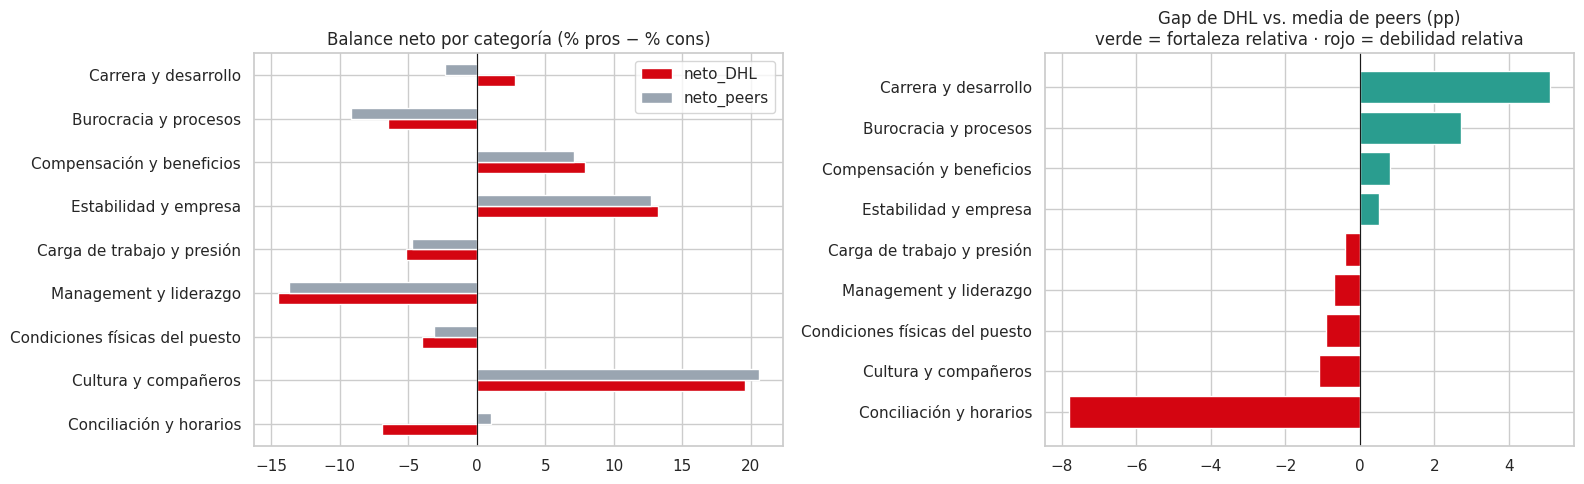

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comp[['neto_DHL', 'neto_peers']].plot(kind='barh', ax=axes[0], color=['#D40511', '#9aa5b1'])
axes[0].axvline(0, c='k', lw=.8); axes[0].set_title('Balance neto por categoría (% pros − % cons)')
colores_gap = ['#2a9d8f' if v > 0 else '#D40511' for v in comp['gap_neto']]
axes[1].barh(comp.index, comp['gap_neto'], color=colores_gap); axes[1].axvline(0, c='k', lw=.8)
axes[1].set_title('Gap de DHL vs. media de peers (pp)\nverde = fortaleza relativa · rojo = debilidad relativa')
plt.tight_layout(); plt.show()

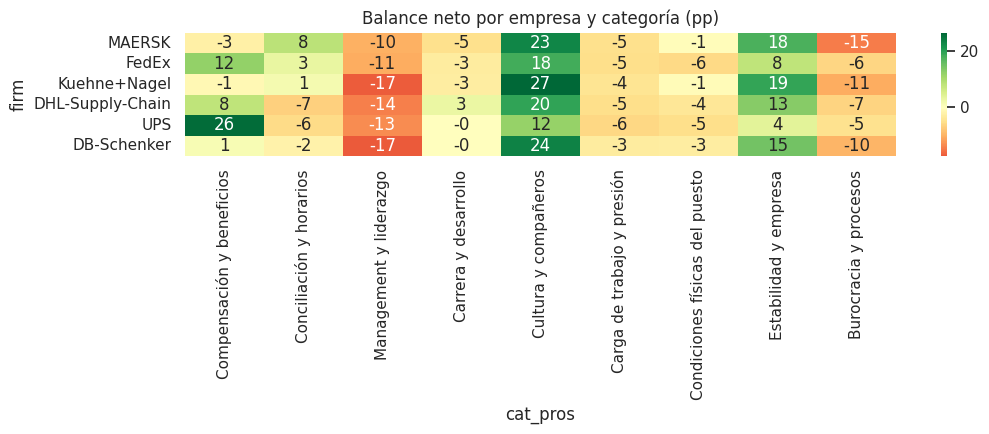

In [90]:
# Heatmap del balance neto por empresa: ¿quién es el referente en cada categoría?
plt.figure(figsize=(11, 4.5))
sns.heatmap(neto.loc[orden], annot=True, fmt='.0f', cmap='RdYlGn', center=0)
plt.title('Balance neto por empresa y categoría (pp)'); plt.tight_layout(); plt.show()

**Lectura de la comparación con peers (balance neto, pp):**
- 🔴 **Conciliación y horarios: −7,8 pp**, la mayor debilidad relativa. DHL la destaca menos como pro (10 % vs 14 %) y se queja más de ella (17 % vs 13 %).
- 🔴 **Management y liderazgo: −0,7 pp neto, +2,2 pp en cons.** Es la queja más frecuente en DHL (18 %); el sector entero sale negativo, pero DHL algo peor.
- 🟢 **Carrera y desarrollo: +5,1 pp**, la mayor fortaleza relativa: 9,3 % de los pros de DHL la mencionan frente a 5,6 % en los peers. Esto **refuta la hipótesis del EDA** (fuga por falta de carrera).
- 🟢 **Burocracia y procesos: +2,7 pp** (menos quejas que los peers, 8 % vs 11 %).
- ⚪ Compensación, estabilidad, cultura, carga de trabajo y condiciones físicas: diferencias < 1,1 pp → **en línea con el mercado**.

### Contraste con rating y recomendación
Si una categoría es de verdad un problema, las reseñas que se quejan de ella deberían puntuar peor.

In [91]:
contraste = (df[df['cat_cons'].isin(CATS)]
    .groupby(['cat_cons', 'es_target'])
    .agg(rating=('overall_rating', 'mean'), pct_no_recomienda=('recommend', lambda s: (s == 'x').mean() * 100), n=('firm', 'size'))
    .round(2).unstack())
contraste

rating       pct_no_recomienda  \
es_target                      DHL-Supply-Chain Peers  DHL-Supply-Chain   
cat_cons                                                                  
Burocracia y procesos                      3.65  3.88             19.29   
Carga de trabajo y presión                 3.81  3.69             15.00   
Carrera y desarrollo                       3.50  3.75             27.27   
Compensación y beneficios                  3.44  3.43             24.69   
Conciliación y horarios                    3.60  3.76             19.93   
Condiciones físicas del puesto             3.36  3.69             31.43   
Cultura y compañeros                       2.92  3.14             73.08   
Estabilidad y empresa                      3.56  3.63             11.11   
Management y liderazgo                     2.75  2.89             47.88   

                                                     n        
es_target                       Peers DHL-Supply-Chain Peers  
cat_cons                                                      
Burocracia y procesos           15.24              140   617  
Carga de trabajo y presión      19.71              140   548  
Carrera y desarrollo            16.63              110   457  
Compensación y beneficios       28.03              239   817  
Conciliación y horarios         17.05              291   991  
Condiciones físicas del puesto  18.23               70   395  
Cultura y compañeros            37.82               26   156  
Estabilidad y empresa           21.98                9    91  
Management y liderazgo          42.95              307   922

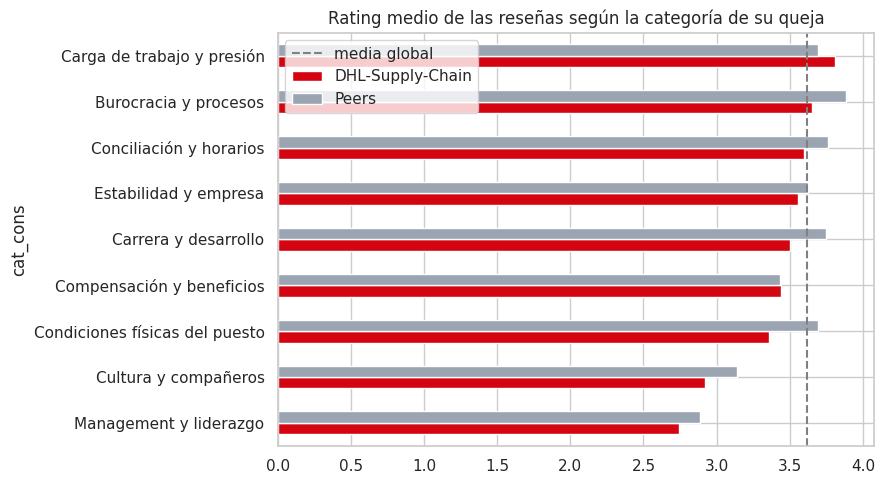

In [92]:
r = df[df['cat_cons'].isin(CATS)].groupby(['cat_cons', 'es_target'])['overall_rating'].mean().unstack()[[TARGET, 'Peers']]
r.sort_values(TARGET).plot(kind='barh', figsize=(9, 5), color=['#D40511', '#9aa5b1'])
plt.axvline(df['overall_rating'].mean(), ls='--', c='grey', label='media global')
plt.title('Rating medio de las reseñas según la categoría de su queja'); plt.legend(); plt.tight_layout(); plt.show()

**Contraste con rating y recomendación:**
- Las quejas de **Management** son las que peor puntúan (DHL 2,75; peers 2,89) y casi la mitad no recomienda la empresa (48 % vs 43 %): es un problema real, no ruido.
- **Conciliación**: queja muy frecuente pero menos grave por reseña (3,60). Es un desgaste continuo más que un motivo de ruptura inmediata.
- **Condiciones físicas**: en DHL arrastran peor valoración que en los peers (3,36 vs 3,69; 31 % no recomienda vs 18 %), aunque con pocas reseñas (n = 70).
- **Carrera**: quienes se quejan de ella en DHL recomiendan menos que en los peers (27 % vs 17 % no recomienda) → la carrera es una fortaleza *en general*, pero quien no la consigue se decepciona más.
- *Cultura* y *Estabilidad* tienen muy pocas quejas en DHL (n = 26 y 9), no se interpretan.

---
## 5. Empleados actuales vs. antiguos

Los cons de quienes se han ido son, en la práctica, **motivos de salida**. Comparamos temas, no sentimiento (los antiguos siempre puntúan más bajo: sesgo de selección).

In [93]:
dhl = df[df['firm'] == TARGET]
act_vs_ant = (pd.crosstab(dhl['cat_cons'], dhl['situacion'], normalize='columns').mul(100)
              .reindex(CATS).round(1))
act_vs_ant['dif_antiguo_menos_actual'] = act_vs_ant['Antiguo'] - act_vs_ant['Actual']
act_vs_ant.sort_values('dif_antiguo_menos_actual', ascending=False)

situacion,Actual,Antiguo,dif_antiguo_menos_actual
cat_cons,,,
Condiciones físicas del puesto,3.2,5.4,2.2
Carrera y desarrollo,5.7,7.7,2.0
Management y liderazgo,17.5,19.1,1.6
Cultura y compañeros,1.1,2.1,1.0
Conciliación y horarios,16.9,17.7,0.8
Estabilidad y empresa,0.2,1.0,0.8
Carga de trabajo y presión,8.2,8.4,0.2
Compensación y beneficios,14.6,13.5,-1.1
Burocracia y procesos,9.6,6.6,-3.0


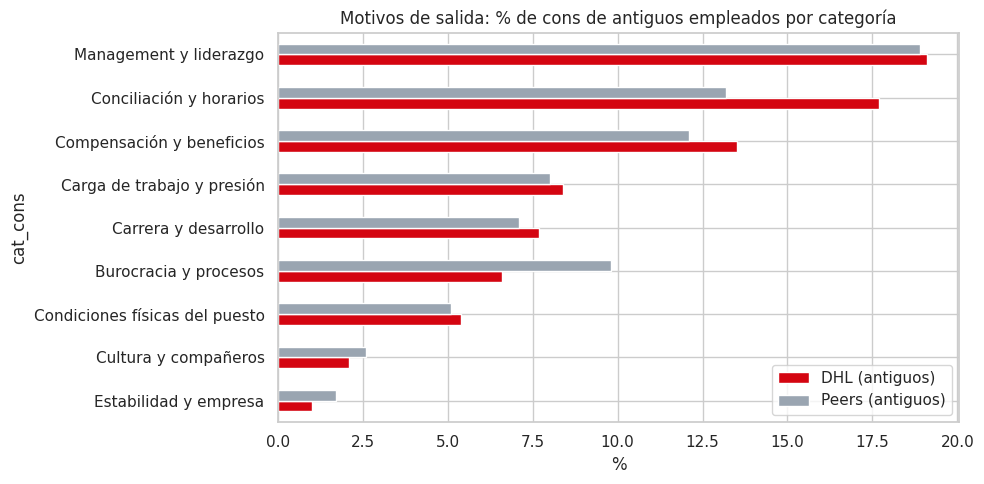

,DHL (antiguos),Peers (antiguos),gap
cat_cons,,,
Conciliación y horarios,17.7,13.2,4.5
Compensación y beneficios,13.5,12.1,1.5
Carrera y desarrollo,7.7,7.1,0.6
Carga de trabajo y presión,8.4,8.0,0.4
Condiciones físicas del puesto,5.4,5.1,0.3
Management y liderazgo,19.1,18.9,0.2
Cultura y compañeros,2.1,2.6,-0.5
Estabilidad y empresa,1.0,1.7,-0.7
Burocracia y procesos,6.6,9.8,-3.2


In [94]:
ant = df[df['situacion'] == 'Antiguo']
salida = pd.DataFrame({
    'DHL (antiguos)':   pd.crosstab(ant['firm'], ant['cat_cons'], normalize='index').mul(100).reindex(columns=CATS, fill_value=0).loc[TARGET],
    'Peers (antiguos)': pd.crosstab(ant['firm'], ant['cat_cons'], normalize='index').mul(100).reindex(columns=CATS, fill_value=0).loc[PEERS].mean()})
salida['gap'] = salida['DHL (antiguos)'] - salida['Peers (antiguos)']
salida = salida.round(1).sort_values('DHL (antiguos)', ascending=True)
salida[['DHL (antiguos)', 'Peers (antiguos)']].plot(kind='barh', figsize=(10, 5), color=['#D40511', '#9aa5b1'])
plt.title('Motivos de salida: % de cons de antiguos empleados por categoría'); plt.xlabel('%'); plt.tight_layout(); plt.show()
salida.sort_values('gap', ascending=False)

In [95]:
# Ejemplos reales de motivos de salida en DHL (para la presentación)
for cat in salida.sort_values('gap', ascending=False).index[:3]:
    print(f'\n=== {cat} ===')
    for t in ant[(ant['firm'] == TARGET) & (ant['cat_cons'] == cat)]['cons'].sample(3, random_state=SEED):
        print('-', t[:220])


=== Conciliación y horarios ===
- Would employ mostly men Could not get anyone for holidays
- No problems faced Sometimes Shift timings can be difficult
- Lots of overtime with very little notice.

=== Compensación y beneficios ===
- No Growth I. Terms of salary
- Only give raises per cost of living goin up so they say
- Benefits 1st year are pretty bad. You are basically paying almost everything with hsa or fsa

=== Carrera y desarrollo ===
- not enough proper training. working 72 hours in six days
- bad structure and no career support
- Fluctuations in business require mobility and flexibility.


**Motivos de salida (antiguos empleados):**
- En DHL, los antiguos mencionan más que los actuales **Condiciones físicas (+2,2 pp), Carrera (+2,0) y Management (+1,6)**: son los temas que acompañan a la decisión de irse.
- Frente a los antiguos de los peers, el gap claro es **Conciliación y horarios: 17,7 % vs 13,2 % (+4,5 pp)**. Ejemplos: *"Lots of overtime with very little notice"*, *"Could not get anyone for holidays"*, *"Shift timings can be difficult"*.
- Compensación (+1,5 pp) es secundaria; Burocracia pesa menos que en los peers (−3,2 pp).
- **Para el plan de retención:** el foco es la gestión de turnos, horas extra y vacaciones.

---
## 6. Matriz de priorización

- **Eje X:** peso de la categoría en los cons de DHL (¿cuánto se habla de ello?).
- **Eje Y:** desventaja frente a peers = % cons DHL − % cons peers (¿estamos peor que el mercado?).

Cuadrante superior derecho = **prioridad alta** (mucho peso y peor que los peers).

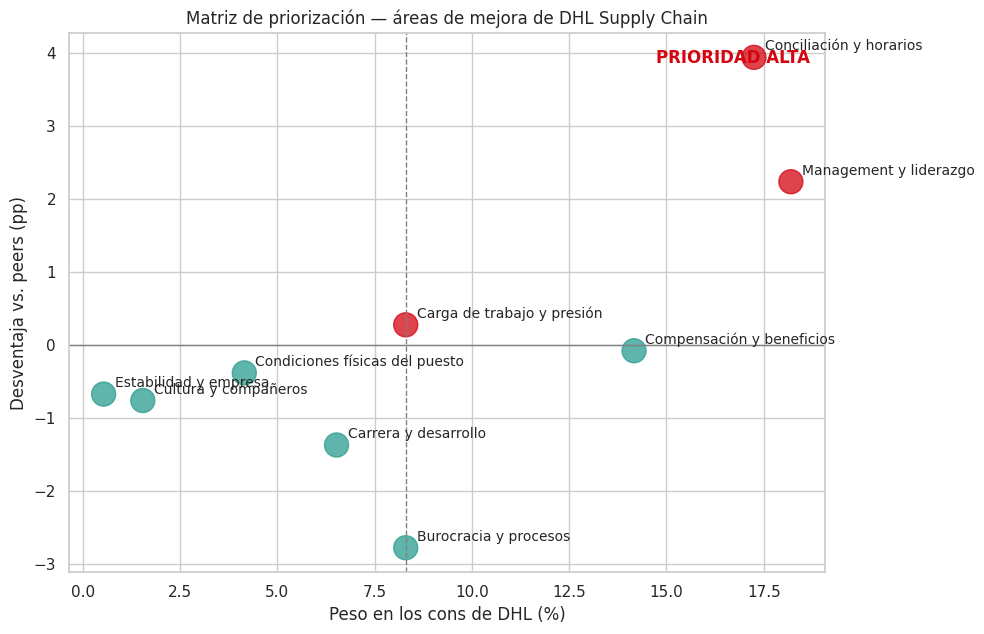

,peso_cons_DHL,desventaja_pp
cat_cons,,
Conciliación y horarios,17.2,3.9
Management y liderazgo,18.2,2.2
Carga de trabajo y presión,8.3,0.3
Compensación y beneficios,14.2,-0.1
Condiciones físicas del puesto,4.1,-0.4
Estabilidad y empresa,0.5,-0.7
Cultura y compañeros,1.5,-0.8
Carrera y desarrollo,6.5,-1.4
Burocracia y procesos,8.3,-2.8


In [96]:
matriz = pd.DataFrame({'peso_cons_DHL': cons_pct.loc[TARGET, CATS],
                       'desventaja_pp': cons_pct.loc[TARGET, CATS] - cons_pct.loc[PEERS, CATS].mean()})
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(matriz['peso_cons_DHL'], matriz['desventaja_pp'], s=300, c=np.where(matriz['desventaja_pp'] > 0, '#D40511', '#2a9d8f'), alpha=.75)
for cat, r in matriz.iterrows():
    ax.annotate(cat, (r['peso_cons_DHL'], r['desventaja_pp']), xytext=(8, 5), textcoords='offset points', fontsize=10)
ax.axhline(0, c='grey', lw=1); ax.axvline(matriz['peso_cons_DHL'].median(), c='grey', lw=1, ls='--')
ax.set_xlabel('Peso en los cons de DHL (%)'); ax.set_ylabel('Desventaja vs. peers (pp)')
ax.set_title('Matriz de priorización — áreas de mejora de DHL Supply Chain')
ax.text(.98, .97, 'PRIORIDAD ALTA', transform=ax.transAxes, ha='right', va='top', color='#D40511', weight='bold')
plt.tight_layout(); plt.show()
matriz.round(1).sort_values('desventaja_pp', ascending=False)

**Prioridades según la matriz:**
1. **Conciliación y horarios** — 17 % de los cons de DHL y +3,9 pp frente a los peers → **prioridad alta**.
2. **Management y liderazgo** — 18 % de los cons y +2,2 pp → **prioridad alta**, y la que más hunde el rating.
3. **Carga de trabajo** (+0,3) y **Compensación** (−0,1) → mucho peso pero igual que el mercado: *mantener*, no son diferenciales.
4. **Burocracia, Carrera, Cultura** → por debajo de los peers en quejas: no requieren inversión prioritaria.

### Extra: evolución pre vs. post 2020

In [97]:
df['periodo'] = np.where(df['anio'] < 2020, 'Pre-2020', '2020-2021')
evo_cat = (df[df['cat_cons'].isin(CATS)]
           .groupby(['es_target', 'periodo'])['cat_cons'].value_counts(normalize=True).mul(100)
           .unstack().T.round(1))
evo_cat

es_target                      DHL-Supply-Chain              Peers         
periodo                               2020-2021 Pre-2020 2020-2021 Pre-2020
cat_cons                                                                   
Burocracia y procesos                      10.2     11.1      12.4     12.2
Carga de trabajo y presión                  9.3     13.2      11.8      9.2
Carrera y desarrollo                        7.8      9.2       8.1     11.4
Compensación y beneficios                  18.5     16.7      15.9     17.2
Conciliación y horarios                    23.9     17.5      20.9     17.6
Condiciones físicas del puesto              5.0      5.9       8.0      7.8
Cultura y compañeros                        2.1      1.7       3.0      3.4
Estabilidad y empresa                       0.6      0.9       1.8      1.8
Management y liderazgo                     22.7     23.8      18.1     19.3

**Evolución pre-2020 vs 2020-2021:** las quejas de **Conciliación** en DHL suben de 17,5 % a **23,9 %** (+6,4 pp, más que en los peers: +3,3). La presión de volumen del COVID/e-commerce se tradujo en horarios y horas extra. En cambio, la **Carga de trabajo** baja en DHL (13,2 → 9,3 %) mientras sube en los peers (9,2 → 11,8 %). El problema no es cuánto se trabaja, sino **cuándo y con qué previsibilidad**.

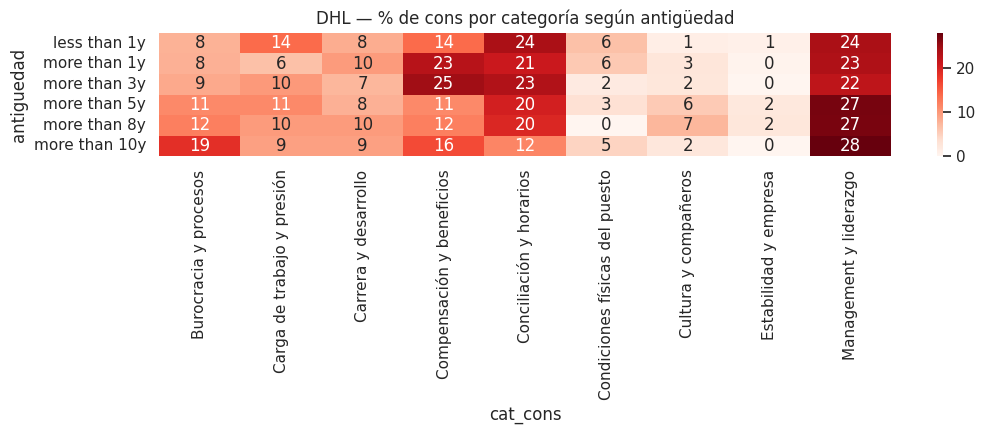

In [98]:
# Extra: categoría de queja por antigüedad en DHL (¿qué preocupa a cada etapa?)
ant_ord2 = ['less than 1y', 'more than 1y', 'more than 3y', 'more than 5y', 'more than 8y', 'more than 10y']
x = dhl[dhl['antiguedad'].isin(ant_ord2) & dhl['cat_cons'].isin(CATS)]
plt.figure(figsize=(11, 4.5))
sns.heatmap(pd.crosstab(x['antiguedad'], x['cat_cons'], normalize='index').mul(100).reindex(ant_ord2),
            annot=True, fmt='.0f', cmap='Reds')
plt.title('DHL — % de cons por categoría según antigüedad'); plt.tight_layout(); plt.show()

**Quejas por antigüedad (DHL):** el mapa de calor muestra qué preocupa en cada etapa. Se lee con cautela, porque algunos tramos tienen pocas reseñas (más de 8 y más de 10 años) y un 38 % de las reseñas no informa la antigüedad. Su uso es complementar el EDA: entre 1 y 8 años, que es donde DHL puntúa por debajo de los peers, conviene vigilar si pesan más la conciliación y el management. Esto concreta a quién dirigir las recomendaciones 1 y 2.

---
## 7. Conclusiones y recomendaciones para RRHH

**Diagnóstico:** DHL Supply Chain es un empleador **de la zona media-baja del sector** (rating 3,52, 4º de 6; 44 % recomienda). Su gran diferencial negativo no es el salario ni la carga de trabajo, sino **la gestión del tiempo (turnos, horas extra, vacaciones) y la calidad de los mandos**.

**Puntos fuertes (para employer branding):**
- **Carrera y desarrollo:** +5,1 pp de balance neto frente a los peers; los empleados destacan formación, promoción interna y crecimiento.
- **Menos burocracia** que la competencia (+2,7 pp).
- **Compensación y estabilidad** en línea o ligeramente por encima del mercado: argumentos sólidos, aunque no diferenciales.
- Los empleados con **más de 10 años** valoran DHL por encima de los peers (3,87 vs 3,80).

**Áreas de mejora prioritarias:**
1. **Conciliación y horarios** (−7,8 pp neto; primer motivo de salida diferencial, +4,5 pp; empeora en 2020-2021).
2. **Management y liderazgo** (queja más frecuente, +2,2 pp vs peers, rating 2,75).
3. **Condiciones físicas del puesto** — vigilar: peor valoradas que en los peers y más citadas por quienes se van.

**Recomendaciones (máx. 3):**
1. **Retención — Planificación de turnos predecible.** Publicar turnos con al menos 2 semanas de antelación, preavisar las horas extra y limitar las obligatorias, y reservar cupos de vacaciones también en *peak season*. KPI: bajar el % de cons de conciliación de los antiguos empleados del 17,7 % al nivel del sector (~13 %).
2. **Gestión — Programa para mandos intermedios.** Formación de supervisores en liderazgo de equipos operativos (trato, reconocimiento, favoritismo), evaluación 360° y una encuesta *pulse* trimestral por centro. KPI: rating medio de las reseñas que mencionan Management.
3. **Atracción — Employer branding centrado en carrera.** Comunicar casos reales de promoción interna y formación, la fortaleza diferencial de DHL, y hacer visible un itinerario de carrera en los años 1-5, que es donde DHL puntúa por debajo de los peers. Así se refuerza la promesa y se evita la decepción de quien no la ve cumplida.

**Limitaciones:**
- Glassdoor no es representativo: sobrerrepresenta a empleados muy satisfechos o muy descontentos.
- Mezcla de países, áreas (almacén, oficina, transporte) y puestos; DHL Supply Chain es solo una entidad del grupo.
- Cada reseña se asigna a **un solo** topic, aunque puede tratar varios; la asignación a categorías requiere revisión manual.
- Ventana limitada a jul-2018 → jun-2021 por falta de reseñas de DHL posteriores; algunas categorías tienen pocas reseñas en DHL (n < 50).

**Próximos pasos:** clasificación multi-etiqueta (*zero-shot*) para captar varios temas por reseña, análisis por país y puesto, y validación con encuesta interna y datos reales de rotación.